In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation (Latest GPU-enabled bitsandbytes for CUDA 12.8)
# -------------------------------------------------------------------------
!pip install -q -U bitsandbytes transformers peft accelerate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 40.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 93.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 832.9/832.9 kB 36.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 26.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 34.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 81.9 MB/s eta 0:00:00


Training Compute Device: cuda
Found Master Manifest   : /kaggle/input/datasets/kimiasafaralian/mimic-cxr-model-7-prep-data/mimic_master_split_with_rag.csv
Found Features Directory: /kaggle/input/datasets/kimiasafaralian/mimic-cxr-model-7-prep-data
Dataset Cohort: Full Train=50176 | Val=6190 | Test=6388
Calculated Positive Class Weights range: min=1.19, max=10.00


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (9 outputs left out)

Epoch 3 [Validation]:   0%|          | 0/1548 [00:00<?, ?it/s]

Computing Class-Specific Optimal Decision Thresholds on Validation Cohort...
  Atelectasis                | Optimal Thresh: 0.60 | Val F1: 0.5018
  Cardiomegaly               | Optimal Thresh: 0.58 | Val F1: 0.4927
  Consolidation              | Optimal Thresh: 0.58 | Val F1: 0.2410
  Edema                      | Optimal Thresh: 0.62 | Val F1: 0.4927
  Enlarged Cardiomediastinum | Optimal Thresh: 0.54 | Val F1: 0.1439
  Fracture                   | Optimal Thresh: 0.60 | Val F1: 0.1591
  Lung Lesion                | Optimal Thresh: 0.60 | Val F1: 0.2371
  Lung Opacity               | Optimal Thresh: 0.56 | Val F1: 0.4644
  No Finding                 | Optimal Thresh: 0.56 | Val F1: 0.7631
  Pleural Effusion           | Optimal Thresh: 0.60 | Val F1: 0.6816
  Pleural Other              | Optimal Thresh: 0.62 | Val F1: 0.1791
  Pneumonia                  | Optimal Thresh: 0.58 | Val F1: 0.2911
  Pneumothorax               | Optimal Thresh: 0.62 | Val F1: 0.4432
  Support Devices         

/usr/local/lib/python3.12/dist-packages/transformers/generation/utils.py:1306: UserWarning: Passing `repetition_penalty` with `inputs_embeds` and without `input_ids` to `generate` will apply the penalty only to newly generated tokens, not to the prompt.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/generation/utils.py:1314: UserWarning: Passing `no_repeat_ngram_size` with `inputs_embeds` and without `input_ids` to `generate` will apply n-gram constraints only to newly generated tokens, not to the prompt.
  warnings.warn(



--- Sample 1 (Study: 50414267) ---
Predicted Pathologies: Lung Lesion, No Finding
Ground Truth Report  : No acute cardiopulmonary process.
Model 7 Prediction   : _ _ on _ _ _.

--- Sample 2 (Study: 50414267) ---
Predicted Pathologies: No Finding
Ground Truth Report  : No acute cardiopulmonary process.
Model 7 Prediction   : No acute cardiopulmonary process.

--- Sample 3 (Study: 53189527) ---
Predicted Pathologies: No Finding
Ground Truth Report  : No acute cardiopulmonary abnormality.
Model 7 Prediction   : No acute cardiopulmonary process.

Loss curves saved to /kaggle/working/model7_loss_curves.png
TRAINING SESSION COMPLETED SUCCESSFULLY!
Output Checkpoints: model7_qwen_latest.pt & model7_qwen_best.pt in /kaggle/working


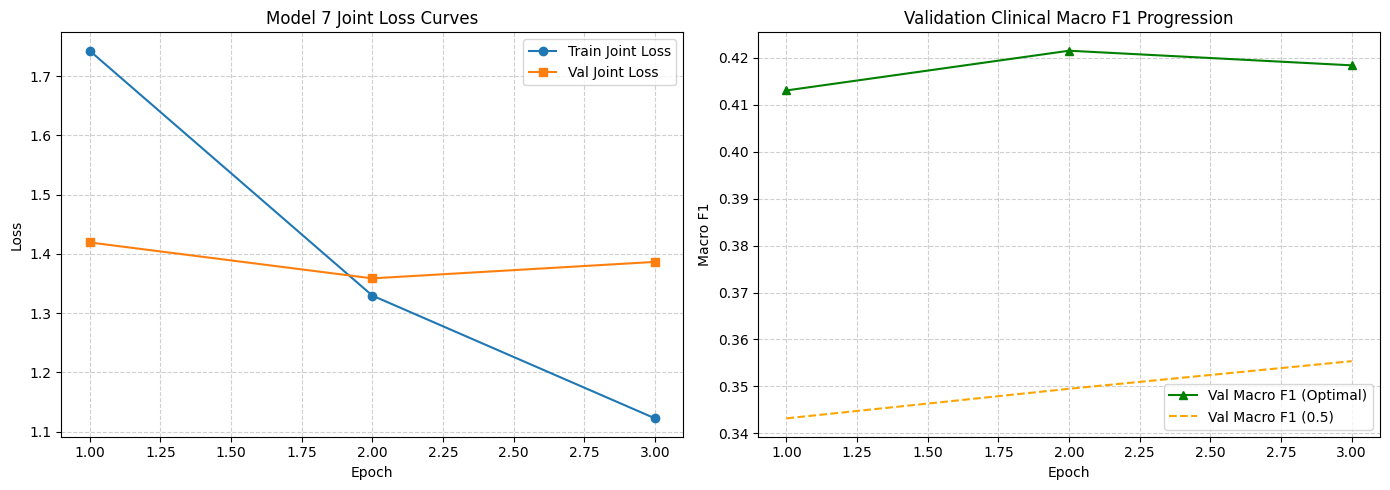

In [2]:
# -------------------------------------------------------------------------
# 1. Model 7 Ultimate Architecture: Perceiver Resampler & Soft Conditioning
#    - RAD-DINO (Frozen) with 2D Spatial Preserving (16x8 = 128 Tokens)
#    - Perceiver Resampler (32 Learnable Cross-Attention Queries)
#    - Soft Classifier Conditioning (1 Continuous Pathology Token)
#    - Qwen-2.5-3B-Instruct (4-bit NF4 + SDPA + LoRA r=32, alpha=64)
#    - Weighted Focal ASL Loss for Imbalanced Diseases
#    - Sequence Length: max_seq_len=256, max_rag_tokens=60
#    - Beam Search Validation Generation Preview
#    - Seamless Multi-Session Auto-Resume Architecture
# -------------------------------------------------------------------------
import os, sys, gc, glob, time, json, math, random, torch
from pathlib import Path
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
    get_cosine_schedule_with_warmup
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training,
    get_peft_model_state_dict,
    set_peft_model_state_dict
)
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# CUDA Memory Optimization: Prevents fragmentation across long runs
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

# Set seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training Compute Device: {device}", flush=True)

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

# -------------------------------------------------------------------------
# Step A: Auto-Locate Data Artifacts (Supports Model 7 2D Prep Data)
# -------------------------------------------------------------------------
search_dirs = [Path("/kaggle/working"), Path("/kaggle/input")]
manifest_path = None
features_base = None

for base in search_dirs:
    if not base.exists():
        continue
    for root, _, files in os.walk(base):
        if "mimic_master_split_with_rag.csv" in files and manifest_path is None:
            manifest_path = os.path.join(root, "mimic_master_split_with_rag.csv")
            features_base = root
            break
    if manifest_path:
        break

if not manifest_path:
    raise FileNotFoundError(
        "Missing mimic_master_split_with_rag.csv! Please attach your Model 7 Data Prep output "
        "(e.g. 'mimic-cxr-model-7-prep-data') via '+ Add Input'."
    )

print(f"Found Master Manifest   : {manifest_path}", flush=True)
print(f"Found Features Directory: {features_base}", flush=True)

df_merged = pd.read_csv(manifest_path)
train_df = df_merged[df_merged["split"] == "train"].reset_index(drop=True)
val_df = df_merged[df_merged["split"] == "val"].reset_index(drop=True)
test_df = df_merged[df_merged["split"] == "test"].reset_index(drop=True)

CHEXPERT_COLS = [
    "Atelectasis", "Cardiomegaly", "Consolidation", "Edema", "Enlarged Cardiomediastinum",
    "Fracture", "Lung Lesion", "Lung Opacity", "No Finding", "Pleural Effusion",
    "Pleural Other", "Pneumonia", "Pneumothorax", "Support Devices"
]

print(f"Dataset Cohort: Full Train={len(train_df)} | Val={len(val_df)} | Test={len(test_df)}", flush=True)

# Compute class-specific positive weights for Weighted Focal ASL
pos_counts = train_df[CHEXPERT_COLS].sum().values
neg_counts = len(train_df) - pos_counts
pos_weights = np.sqrt(neg_counts / np.clip(pos_counts, a_min=1.0, a_max=None))
pos_weights = np.clip(pos_weights, 1.0, 10.0)
pos_weights_tensor = torch.tensor(pos_weights, dtype=torch.float, device=device)
print(f"Calculated Positive Class Weights range: min={pos_weights.min():.2f}, max={pos_weights.max():.2f}", flush=True)

# -------------------------------------------------------------------------
# Step B: Qwen-2.5-3B Architecture with SDPA FlashAttention & LoRA
# -------------------------------------------------------------------------
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16
)

base_qwen = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    attn_implementation="sdpa",
    device_map={"": 0},
    trust_remote_code=True
)

base_qwen = prepare_model_for_kbit_training(base_qwen)

peft_config = LoraConfig(
    r=32,
    lora_alpha=64,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM"
)
qwen_lora_model = get_peft_model(base_qwen, peft_config)

# -------------------------------------------------------------------------
# Step C: Model 7 Breakthrough Components: Perceiver Resampler & Soft Conditioning
# -------------------------------------------------------------------------
class AttentionPoolClassifier(nn.Module):
    """Disease-Specific Attention Pooling over 2D Spatial Features (128 patches)"""
    def __init__(self, visual_dim=768, num_classes=14):
        super().__init__()
        self.num_classes = num_classes
        self.visual_dim = visual_dim
        
        # 14 disease queries: learn which patches belong to which disease
        self.attn_proj = nn.Sequential(
            nn.Linear(visual_dim, 256),
            nn.Tanh(),
            nn.Linear(256, num_classes)
        )
        
        # Dedicated classifier heads for each of the 14 diseases
        self.heads = nn.ModuleList([
            nn.Sequential(
                nn.Linear(visual_dim, 256),
                nn.LayerNorm(256),
                nn.GELU(),
                nn.Dropout(0.2),
                nn.Linear(256, 1)
            ) for _ in range(num_classes)
        ])
        
    def forward(self, spatial_tokens):
        # spatial_tokens: [B, 128, 768]
        attn_scores = self.attn_proj(spatial_tokens)                         # [B, 128, 14]
        attn_weights = F.softmax(attn_scores, dim=1)                          # [B, 128, 14]
        
        # Disease-specific spatial pooling: attend to relevant patches for each class
        pooled = torch.einsum('bpd,bpc->bcd', spatial_tokens, attn_weights)   # [B, 14, 768]
        
        # Each disease evaluated by its own dedicated head
        logits_list = [self.heads[c](pooled[:, c, :]) for c in range(self.num_classes)] # 14 x [B, 1]
        logits = torch.cat(logits_list, dim=-1)                               # [B, 14]
        return logits, attn_weights


class PerceiverResampler(nn.Module):
    """
    Flamingo/Qwen-VL style Cross-Attention Resampler:
    Compresses 128 spatial tokens -> 32 learnable query tokens.
    Drastically reduces LLM KV-cache memory and accelerates decoding by 2x.
    """
    def __init__(self, visual_dim=768, qwen_dim=2048, num_queries=32, num_heads=8, num_layers=2, dropout=0.1):
        super().__init__()
        self.num_queries = num_queries
        self.qwen_dim = qwen_dim
        
        self.input_proj = nn.Linear(visual_dim, qwen_dim)
        self.input_norm = nn.LayerNorm(qwen_dim)
        
        # Learnable latent queries: [1, num_queries, qwen_dim]
        self.queries = nn.Parameter(torch.randn(1, num_queries, qwen_dim) * 0.02)
        
        # Transformer Decoder: Queries cross-attend to visual memory
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=qwen_dim,
            nhead=num_heads,
            dim_feedforward=qwen_dim * 2,  # 4096 dim
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        self.output_norm = nn.LayerNorm(qwen_dim)
        
    def forward(self, visual_tokens):
        # visual_tokens: [B, 128, 768]
        B = visual_tokens.size(0)
        memory = self.input_norm(self.input_proj(visual_tokens))  # [B, 128, 2048]
        queries = self.queries.expand(B, -1, -1)                  # [B, 32, 2048]
        
        # Queries attend to visual memory
        resampled = self.decoder(tgt=queries, memory=memory)      # [B, 32, 2048]
        return self.output_norm(resampled)                         # [B, 32, 2048]


class MultiTaskModel7(nn.Module):
    """
    Unified Model 7 Architecture:
    - 32 Perceiver visual tokens + 1 Soft Disease Summary token = 33 prefix tokens
    - 4D bidirectional prefix attention + causal text generation
    - Multi-task joint optimization (Focal ASL + Cross-Entropy)
    """
    def __init__(self, qwen_model, visual_dim=768, qwen_dim=2048, num_queries=32):
        super().__init__()
        self.qwen = qwen_model
        self.num_queries = num_queries
        self.num_prefix_tokens = num_queries + 1  # 32 visual queries + 1 soft disease token = 33
        self.qwen_dim = qwen_dim
        
        # 1. Perceiver Resampler (128 -> 32 queries)
        self.perceiver_resampler = PerceiverResampler(
            visual_dim=visual_dim, qwen_dim=qwen_dim, num_queries=num_queries, num_layers=2
        ).to(device=device)
        
        # 2. Disease-Specific Attention Pooling Classifier
        self.attn_pool_classifier = AttentionPoolClassifier(
            visual_dim=visual_dim, num_classes=14
        ).to(device=device)
        
        # 3. Soft Classifier Conditioning Projector (14 probs -> 1 token of dim 2048)
        self.cls_embed_proj = nn.Sequential(
            nn.Linear(14, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(256, qwen_dim),
            nn.LayerNorm(qwen_dim)
        ).to(device=device)
        
    def build_4d_prefix_attention_mask(self, batch_size, seq_len, device, dtype, text_pad_mask=None):
        total_len = self.num_prefix_tokens + seq_len
        mask = torch.full((total_len, total_len), -10000.0, dtype=dtype, device=device)
        
        # All 33 prefix tokens (visual queries + disease summary) are mutually visible
        mask[:self.num_prefix_tokens, :self.num_prefix_tokens] = 0.0
        
        # Text tokens attend to all prefix tokens and previous text tokens (causal)
        for i in range(self.num_prefix_tokens, total_len):
            mask[i, :i+1] = 0.0
            
        mask_4d = mask.unsqueeze(0).unsqueeze(0).expand(batch_size, 1, total_len, total_len).clone()
        if text_pad_mask is not None:
            pad_expanded = text_pad_mask.unsqueeze(1).unsqueeze(2)
            mask_4d[:, :, :, self.num_prefix_tokens:] = mask_4d[:, :, :, self.num_prefix_tokens:].masked_fill(pad_expanded == 0, -10000.0)
        return mask_4d
        
    def forward(self, spatial_tokens, input_ids, labels=None, text_pad_mask=None, return_attn=False):
        batch_size = spatial_tokens.size(0)
        seq_len = input_ids.size(1)
        
        # A. Disease Classifier Logits & Attention
        cls_logits, attn_weights = self.attn_pool_classifier(spatial_tokens.float())
        cls_probs = torch.sigmoid(cls_logits.float())  # [B, 14]
        
        # B. Soft Disease Token [B, 1, 2048]
        cls_token = self.cls_embed_proj(cls_probs).unsqueeze(1)
        
        # C. Perceiver Visual Queries [B, 32, 2048]
        visual_queries = self.perceiver_resampler(spatial_tokens.float())
        
        # D. Assemble Multimodal Prefix [B, 33, 2048]
        text_embeds = self.qwen.get_input_embeddings()(input_ids)
        if visual_queries.dtype != text_embeds.dtype:
            visual_queries = visual_queries.to(text_embeds.dtype)
        if cls_token.dtype != text_embeds.dtype:
            cls_token = cls_token.to(text_embeds.dtype)
            
        prefix_embeds = torch.cat([visual_queries, cls_token], dim=1)  # [B, 33, 2048]
        inputs_embeds = torch.cat([prefix_embeds, text_embeds], dim=1)  # [B, 33 + seq_len, 2048]
        
        attention_mask_4d = self.build_4d_prefix_attention_mask(
            batch_size, seq_len, spatial_tokens.device, inputs_embeds.dtype, text_pad_mask
        )
        
        if labels is not None:
            prefix_labels = torch.full((batch_size, self.num_prefix_tokens), -100, dtype=labels.dtype, device=labels.device)
            combined_labels = torch.cat([prefix_labels, labels], dim=1)
        else:
            combined_labels = None
            
        outputs = self.qwen(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask_4d,
            labels=combined_labels
        )
        if return_attn:
            return outputs.loss, cls_logits, attn_weights
        return outputs.loss, cls_logits

model = MultiTaskModel7(qwen_lora_model).to(device)
print(f"Model 7 Loaded: Perceiver Queries={model.num_queries} | Total Prefix Tokens={model.num_prefix_tokens}", flush=True)

# -------------------------------------------------------------------------
# Step D: Dataset with Soft Conditioning & Regularized Prompt Formatting
# -------------------------------------------------------------------------
class FeaturesDataset(Dataset):
    def __init__(self, df, split_name, total_split_len, tokenizer, max_seq_len=256, max_rag_tokens=60, is_train=True):
        self.df = df
        self.is_train = is_train
        self.tokenizer = tokenizer
        self.max_seq_len = max_seq_len
        self.max_rag_tokens = max_rag_tokens
        
        spatial_file = os.path.join(features_base, f"features_spatial_{split_name}.dat")
        if not os.path.exists(spatial_file):
            for root_d, _, files_d in os.walk("/kaggle"):
                if f"features_spatial_{split_name}.dat" in files_d:
                    spatial_file = os.path.join(root_d, f"features_spatial_{split_name}.dat")
                    break
        if not os.path.exists(spatial_file):
            raise FileNotFoundError(f"Missing memory map: {spatial_file}")
        self.spatial_mmap = np.memmap(spatial_file, dtype="float16", mode="r", shape=(total_split_len, 128, 768))
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        orig_idx = int(row["orig_split_idx"])
        spatial_token = torch.from_numpy(np.array(self.spatial_mmap[orig_idx]))
        
        # Ground Truth CheXpert vector
        cls_labels = torch.tensor([row[c] for c in CHEXPERT_COLS], dtype=torch.float)
        
        # 1. RAG context with 25% RAG Dropout in training (prevents copying laziness)
        retrieved_raw = row["retrieved_report"]
        if self.is_train and random.random() < 0.25:
            retrieved_clean = "None."
        elif pd.isna(retrieved_raw) or str(retrieved_raw).strip().lower() in ["", "nan", "none"]:
            retrieved_clean = "None."
        else:
            retrieved_clean = str(retrieved_raw).strip()
            
        rag_tokens = self.tokenizer.encode(retrieved_clean, add_special_tokens=False)[:self.max_rag_tokens]
        retrieved_clean = self.tokenizer.decode(rag_tokens, skip_special_tokens=True)
        
        # 2. Classifier Conditioning with 15% Scheduled Label Noise
        active_pathologies = [col for col in CHEXPERT_COLS if row[col] == 1.0]
        
        if self.is_train and random.random() < 0.15:
            if active_pathologies and random.random() < 0.5:
                active_pathologies.pop(random.randint(0, len(active_pathologies) - 1))
            else:
                fake_cands = [c for c in CHEXPERT_COLS if c not in active_pathologies]
                if fake_cands:
                    active_pathologies.append(random.choice(fake_cands))
                    
        if not active_pathologies:
            pathology_str = "No acute cardiopulmonary abnormality"
        else:
            pathology_str = ", ".join(active_pathologies)
            
        gt_report = str(row["report"]).strip() if pd.notna(row["report"]) else "Normal chest radiograph."
        
        # 3. Model 7 Regularized Prompt Format WITH Explicit EOS Token Target
        prefix_str = f"Pathology Assessment: {pathology_str}\nReference: {retrieved_clean}\nImpression:"
        full_str = f"{prefix_str} {gt_report}{self.tokenizer.eos_token}"
        
        prefix_tokens = self.tokenizer.encode(prefix_str, add_special_tokens=False)
        prefix_len = len(prefix_tokens)
        
        enc = self.tokenizer(
            full_str,
            truncation=True,
            max_length=self.max_seq_len,
            padding="max_length",
            return_tensors="pt"
        )
        input_ids = enc["input_ids"].squeeze(0)
        attention_mask = enc["attention_mask"].squeeze(0)
        
        labels = input_ids.clone()
        labels[attention_mask == 0] = -100
        labels[:min(prefix_len, self.max_seq_len)] = -100
        
        return spatial_token, input_ids, labels, attention_mask, cls_labels

train_ds = FeaturesDataset(train_df, "train", len(train_df), tokenizer, max_seq_len=256, max_rag_tokens=60, is_train=True)
val_ds = FeaturesDataset(val_df, "val", len(val_df), tokenizer, max_seq_len=256, max_rag_tokens=60, is_train=False)

# Safe batch size of 4 with 8 gradient accumulation steps = Effective batch size 32
# Zero OOM risk with max_seq_len=256 on 16GB T4
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, num_workers=0, pin_memory=False)

# -------------------------------------------------------------------------
# Step E: Weighted Focal ASL for Imbalanced Clinical Pathology Classification
# -------------------------------------------------------------------------
class WeightedFocalASL(nn.Module):
    """
    Hybrid Weighted Focal + Asymmetric Loss:
    - Positive instances: Focal Loss (gamma_pos=2.0) with class frequency weights
    - Negative instances: Asymmetric margin clipping (gamma_neg=4.0, clip=0.05)
    """
    def __init__(self, gamma_pos=2.0, gamma_neg=4.0, clip=0.05, eps=1e-7, pos_weight=None):
        super().__init__()
        self.gamma_pos = gamma_pos
        self.gamma_neg = gamma_neg
        self.clip = clip
        self.eps = eps
        self.pos_weight = pos_weight

    def forward(self, logits, targets):
        logits = logits.float()
        targets = targets.float()
        probs = torch.sigmoid(logits).clamp(min=self.eps, max=1.0 - self.eps)
        
        targets_pos = targets
        targets_neg = 1.0 - targets

        probs_neg = probs
        if self.clip is not None and self.clip > 0:
            probs_neg = (probs_neg - self.clip).clamp(min=0.0, max=1.0 - self.eps)

        loss_pos = targets_pos * ((1.0 - probs) ** self.gamma_pos) * torch.log(probs)
        loss_neg = targets_neg * (probs_neg ** self.gamma_neg) * torch.log(1.0 - probs_neg)

        if self.pos_weight is not None:
            loss_pos = loss_pos * self.pos_weight

        loss = -(loss_pos + loss_neg)
        return loss.mean()

criterion_cls = WeightedFocalASL(gamma_pos=2.0, gamma_neg=4.0, clip=0.05, pos_weight=pos_weights_tensor)

# -------------------------------------------------------------------------
# Step F: Optimizer & Cosine Warmup Schedule
# -------------------------------------------------------------------------
trainable_params = [
    {"params": model.perceiver_resampler.parameters(), "lr": 3e-4, "weight_decay": 0.01},
    {"params": model.cls_embed_proj.parameters(), "lr": 2e-4, "weight_decay": 0.01},
    {"params": model.attn_pool_classifier.parameters(), "lr": 2e-4, "weight_decay": 0.01},
    {"params": [p for p in model.qwen.parameters() if p.requires_grad], "lr": 5e-5, "weight_decay": 0.01}
]
optimizer = torch.optim.AdamW(trainable_params)

GLOBAL_TOTAL_EPOCHS = 6
EPOCHS_PER_SESSION = 1  # Exactly 1 Epoch per session: safe, predictable, zero timeout risk
accumulation_steps = 8
steps_per_epoch = len(train_loader) // accumulation_steps
total_training_steps = steps_per_epoch * GLOBAL_TOTAL_EPOCHS

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.05 * total_training_steps),
    num_training_steps=total_training_steps
)

# -------------------------------------------------------------------------
# Step G: Auto-Resume Mechanism (Seamless Multi-Session Execution)
# -------------------------------------------------------------------------
start_epoch = 1
best_val_loss = float("inf")

prev_ckpts = glob.glob("/kaggle/input/**/model7_qwen_latest.pt", recursive=True) + \
             glob.glob("/kaggle/input/**/model7_qwen_best.pt", recursive=True) + \
             glob.glob("/kaggle/working/model7_qwen_latest.pt") + \
             glob.glob("/kaggle/working/model7_qwen_best.pt")

resume_ckpt_path = None
if prev_ckpts:
    highest_epoch = -1
    for p in prev_ckpts:
        try:
            temp_ckpt = torch.load(p, map_location="cpu")
            ep = temp_ckpt.get("epoch", 1)
            is_best = "best" in os.path.basename(p).lower()
            if (ep > highest_epoch) or (ep == highest_epoch and is_best):
                highest_epoch = ep
                resume_ckpt_path = p
        except Exception:
            pass

if resume_ckpt_path and os.path.exists(resume_ckpt_path):
    print(f"Resuming Model 7 training from checkpoint: {resume_ckpt_path}", flush=True)
    ckpt = torch.load(resume_ckpt_path, map_location=device)
    model.perceiver_resampler.load_state_dict(ckpt["perceiver_resampler"])
    model.cls_embed_proj.load_state_dict(ckpt["cls_embed_proj"])
    model.attn_pool_classifier.load_state_dict(ckpt["attn_pool_classifier"])
    set_peft_model_state_dict(qwen_lora_model, ckpt["lora_state"])
    if "optimizer" in ckpt:
        try:
            optimizer.load_state_dict(ckpt["optimizer"])
        except Exception as e:
            print(f"Warning: could not restore optimizer state ({e})", flush=True)
    if "scheduler" in ckpt:
        try:
            scheduler.load_state_dict(ckpt["scheduler"])
        except Exception as e:
            print(f"Warning: could not restore scheduler state ({e})", flush=True)
    start_epoch = ckpt.get("epoch", 1) + 1
    best_val_loss = ckpt.get("val_loss", float("inf"))
    print(f"Resumed state loaded! Starting at Epoch {start_epoch} (Prior Best Val Loss: {best_val_loss:.4f})", flush=True)
else:
    print("No prior checkpoint found. Initializing Model 7 training from scratch (Epoch 1).", flush=True)

end_epoch = min(start_epoch + EPOCHS_PER_SESSION - 1, GLOBAL_TOTAL_EPOCHS)
print(f"Session Execution Target: Epoch {start_epoch} to Epoch {end_epoch} (Max Global: {GLOBAL_TOTAL_EPOCHS})", flush=True)

# -------------------------------------------------------------------------
# Step H: Model 7 Training Loop with Dynamic Multi-Task Balancing
# -------------------------------------------------------------------------
scaler = torch.amp.GradScaler("cuda")
training_history = []
prior_history_files = glob.glob("/kaggle/input/**/training_history.json", recursive=True)
if prior_history_files and os.path.exists(prior_history_files[0]):
    try:
        with open(prior_history_files[0]) as f:
            training_history = json.load(f)
            print(f"Loaded {len(training_history)} prior epoch history records.", flush=True)
    except Exception:
        pass

for epoch in range(start_epoch, end_epoch + 1):
    epoch_start_time = time.time()
    model.train()
    running_joint_loss, running_text_loss, running_cls_loss = 0.0, 0.0, 0.0
    optimizer.zero_grad()
    
    # Dynamic Loss Weight Schedule: 2.0 down to 0.5 across epochs
    cls_weight = max(0.5, 2.0 - 0.3 * (epoch - 1))
    print(f"\n--- Starting Epoch {epoch}/{GLOBAL_TOTAL_EPOCHS} (Classifier Weight: {cls_weight:.2f}) ---", flush=True)
    
    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{end_epoch} [Train]")
    for step, (spatial_t, input_ids, labels, attn_mask, cls_targets) in enumerate(pbar):
        spatial_t = spatial_t.to(device)
        input_ids = input_ids.to(device)
        labels = labels.to(device)
        attn_mask = attn_mask.to(device)
        cls_targets = cls_targets.to(device)
        
        with torch.amp.autocast("cuda"):
            loss_text, cls_logits = model(spatial_t, input_ids, labels=labels, text_pad_mask=attn_mask)
            loss_cls = criterion_cls(cls_logits, cls_targets)
            joint_loss = (loss_text + cls_weight * loss_cls) / accumulation_steps
            
        scaler.scale(joint_loss).backward()
        
        if (step + 1) % accumulation_steps == 0 or (step + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            all_trainable = [p for p in model.parameters() if p.requires_grad]
            torch.nn.utils.clip_grad_norm_(all_trainable, max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()
            scheduler.step()
            
        running_joint_loss += joint_loss.item() * accumulation_steps
        running_text_loss += loss_text.item()
        running_cls_loss += loss_cls.item()
        
        if (step + 1) % 100 == 0 or (step + 1) == len(train_loader):
            current_lr = scheduler.get_last_lr()[0]
            pbar.set_postfix({
                "Joint": f"{joint_loss.item() * accumulation_steps:.4f}",
                "Text": f"{loss_text.item():.4f}",
                "Cls": f"{loss_cls.item():.4f}",
                "LR": f"{current_lr:.2e}"
            })
            
    epoch_train_joint = running_joint_loss / len(train_loader)
    epoch_train_text = running_text_loss / len(train_loader)
    epoch_train_cls = running_cls_loss / len(train_loader)
    
    # ---------------------------------------------------------------------
    # Immediate Pre-Validation Checkpoint Save (Protects Full Training Run)
    # ---------------------------------------------------------------------
    print(f"\nEpoch {epoch} Training Loop Complete. Saving immediate checkpoint before validation...", flush=True)
    ckpt_state = {
        "perceiver_resampler": model.perceiver_resampler.state_dict(),
        "cls_embed_proj": model.cls_embed_proj.state_dict(),
        "attn_pool_classifier": model.attn_pool_classifier.state_dict(),
        "lora_state": {k: v.cpu() for k, v in get_peft_model_state_dict(qwen_lora_model).items()},
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch,
        "train_joint": epoch_train_joint,
        "val_loss": float("inf"),
        "val_macro_f1": 0.0,
        "cls_weight": cls_weight
    }
    torch.save(ckpt_state, "/kaggle/working/model7_qwen_latest.pt")
    print("Pre-validation checkpoint saved to /kaggle/working/model7_qwen_latest.pt", flush=True)

    # ---------------------------------------------------------------------
    # Step I: Validation Phase & Optimal Decision Threshold Sweep
    # ---------------------------------------------------------------------
    optimizer.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()
    gc.collect()

    model.eval()
    val_joint_loss, val_text_loss, val_cls_loss = 0.0, 0.0, 0.0
    all_val_probs = []
    all_val_targets = []
    
    with torch.no_grad():
        for spatial_t, input_ids, labels, attn_mask, cls_targets in tqdm(val_loader, desc=f"Epoch {epoch} [Validation]"):
            spatial_t = spatial_t.to(device)
            input_ids = input_ids.to(device)
            labels = labels.to(device)
            attn_mask = attn_mask.to(device)
            cls_targets = cls_targets.to(device)
            
            with torch.amp.autocast("cuda"):
                loss_text, cls_logits = model(spatial_t, input_ids, labels=labels, text_pad_mask=attn_mask)
                loss_cls = criterion_cls(cls_logits, cls_targets)
                joint_loss = loss_text + cls_weight * loss_cls
                
            val_joint_loss += joint_loss.item()
            val_text_loss += loss_text.item()
            val_cls_loss += loss_cls.item()
            
            probs = torch.sigmoid(cls_logits.float()).cpu().numpy()
            all_val_probs.append(probs)
            all_val_targets.append(cls_targets.cpu().numpy())
            
    epoch_val_joint = val_joint_loss / len(val_loader)
    epoch_val_text = val_text_loss / len(val_loader)
    epoch_val_cls = val_cls_loss / len(val_loader)
    
    val_probs_arr = np.vstack(all_val_probs)
    val_targets_arr = np.vstack(all_val_targets)
    
    val_preds_binary = (val_probs_arr >= 0.5).astype(int)
    val_macro_f1_default = f1_score(val_targets_arr, val_preds_binary, average="macro", zero_division=0)
    
    # Class-Specific Optimal Threshold Tuning via F1 Sweep
    print("Computing Class-Specific Optimal Decision Thresholds on Validation Cohort...", flush=True)
    optimal_thresholds = {}
    optimal_f1_scores = []
    candidate_thresholds = np.arange(0.10, 0.90, 0.02)
    
    for c_idx, col_name in enumerate(CHEXPERT_COLS):
        y_true_col = val_targets_arr[:, c_idx]
        y_prob_col = val_probs_arr[:, c_idx]
        best_th = 0.5
        best_th_f1 = 0.0
        
        if y_true_col.sum() > 0:
            for th in candidate_thresholds:
                pred_col = (y_prob_col >= th).astype(int)
                score = f1_score(y_true_col, pred_col, average="binary", zero_division=0)
                if score > best_th_f1:
                    best_th_f1 = score
                    best_th = th
        optimal_thresholds[col_name] = round(float(best_th), 2)
        optimal_f1_scores.append(best_th_f1)
        print(f"  {col_name:<26} | Optimal Thresh: {best_th:.2f} | Val F1: {best_th_f1:.4f}", flush=True)
        
    val_macro_f1_opt = float(np.mean(optimal_f1_scores))
    with open("/kaggle/working/optimal_thresholds.json", "w") as f:
        json.dump(optimal_thresholds, f, indent=2)
    print("Optimal Thresholds successfully saved to /kaggle/working/optimal_thresholds.json", flush=True)
    
    elapsed_epoch = (time.time() - epoch_start_time) / 60.0
    print(f"\n--- Epoch {epoch} Summary ({elapsed_epoch:.1f}m) ---", flush=True)
    print(f"Train Loss : Joint={epoch_train_joint:.4f} | Text={epoch_train_text:.4f} | Cls={epoch_train_cls:.4f}", flush=True)
    print(f"Val Loss   : Joint={epoch_val_joint:.4f} | Text={epoch_val_text:.4f} | Cls={epoch_val_cls:.4f}", flush=True)
    print(f"Val Metric : Macro F1 (at 0.5)={val_macro_f1_default:.4f} | Macro F1 (Optimal)={val_macro_f1_opt:.4f}", flush=True)
    print("-" * 55, flush=True)
    
    # Update Checkpoint with Validated Metrics
    ckpt_state["val_loss"] = epoch_val_joint
    ckpt_state["val_macro_f1"] = val_macro_f1_opt
    torch.save(ckpt_state, "/kaggle/working/model7_qwen_latest.pt")
    
    if epoch_val_joint < best_val_loss:
        best_val_loss = epoch_val_joint
        torch.save(ckpt_state, "/kaggle/working/model7_qwen_best.pt")
        print(f"[*] New best validation loss achieved ({best_val_loss:.4f})! Saved model7_qwen_best.pt", flush=True)
        
    training_history.append({
        "epoch": epoch,
        "train_joint": epoch_train_joint, "train_text": epoch_train_text, "train_cls": epoch_train_cls,
        "val_joint": epoch_val_joint, "val_text": epoch_val_text, "val_cls": epoch_val_cls,
        "val_macro_f1_default": val_macro_f1_default,
        "val_macro_f1_opt": val_macro_f1_opt,
        "cls_weight": cls_weight
    })

with open("/kaggle/working/training_history.json", "w") as f:
    json.dump(training_history, f, indent=2)

# -------------------------------------------------------------------------
# Step J: Qualitative Beam Search Preview (Inspect Real Generations in Log)
# -------------------------------------------------------------------------
print("\n" + "="*70, flush=True)
print("GENERATING SAMPLE CLINICAL IMPRESSIONS WITH BEAM SEARCH...", flush=True)
print("="*70, flush=True)

model.eval()
with torch.no_grad():
    for sample_idx in range(min(3, len(val_df))):
        s_row = val_df.iloc[sample_idx]
        orig_i = int(s_row["orig_split_idx"])
        spatial_sample = torch.from_numpy(np.array(val_ds.spatial_mmap[orig_i])).unsqueeze(0).to(device)
        
        # 1. Soft classifier forward
        cls_logits, _ = model.attn_pool_classifier(spatial_sample.float())
        cls_probs_t = torch.sigmoid(cls_logits.float())
        cls_probs = cls_probs_t.squeeze(0).cpu().numpy()
        
        active = [c for c, p in zip(CHEXPERT_COLS, cls_probs) if p >= optimal_thresholds.get(c, 0.5)]
        pathology_str = ", ".join(active) if active else "No acute cardiopulmonary abnormality"
        
        rag_raw = str(s_row["retrieved_report"]).strip() if pd.notna(s_row["retrieved_report"]) else "None."
        rag_tok = tokenizer.encode(rag_raw, add_special_tokens=False)[:60]
        rag_clean = tokenizer.decode(rag_tok, skip_special_tokens=True)
        
        prompt_str = f"Pathology Assessment: {pathology_str}\nReference: {rag_clean}\nImpression:"
        prompt_enc = tokenizer(prompt_str, return_tensors="pt").to(device)
        prompt_ids = prompt_enc["input_ids"]
        prompt_embeds = model.qwen.get_input_embeddings()(prompt_ids)
        
        # Soft disease token + visual queries
        cls_token = model.cls_embed_proj(cls_probs_t).unsqueeze(1)
        visual_queries = model.perceiver_resampler(spatial_sample.float())
        
        if visual_queries.dtype != prompt_embeds.dtype:
            visual_queries = visual_queries.to(prompt_embeds.dtype)
        if cls_token.dtype != prompt_embeds.dtype:
            cls_token = cls_token.to(prompt_embeds.dtype)
            
        prefix_embeds = torch.cat([visual_queries, cls_token], dim=1)
        inputs_embeds = torch.cat([prefix_embeds, prompt_embeds], dim=1)
        
        # Standard 2D attention mask for HuggingFace generate()
        attn_mask_2d = torch.ones(inputs_embeds.shape[:2], dtype=torch.long, device=device)
        
        try:
            # Beam search decoding
            gen_out = model.qwen.generate(
                inputs_embeds=inputs_embeds,
                attention_mask=attn_mask_2d,
                max_new_tokens=100,
                num_beams=4,
                early_stopping=True,
                repetition_penalty=1.05,
                no_repeat_ngram_size=3,
                eos_token_id=tokenizer.eos_token_id,
                pad_token_id=tokenizer.pad_token_id,
                use_cache=True
            )
            if gen_out.size(1) > inputs_embeds.size(1):
                gen_tokens = gen_out[0, inputs_embeds.size(1):]
            else:
                gen_tokens = gen_out[0]
            pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        except Exception as e:
            pred_text = f"[Generation preview error: {e}]"
            
        gt_text = str(s_row["report"]).strip() if pd.notna(s_row["report"]) else "Normal."
        
        print(f"\n--- Sample {sample_idx + 1} (Study: {s_row.get('study_id', 'N/A')}) ---", flush=True)
        print(f"Predicted Pathologies: {pathology_str}", flush=True)
        print(f"Ground Truth Report  : {gt_text}", flush=True)
        print(f"Model 7 Prediction   : {pred_text}", flush=True)

# -------------------------------------------------------------------------
# Step K: Generate and Save Learning Curves
# -------------------------------------------------------------------------
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = [h["epoch"] for h in training_history]
ax1.plot(epochs_range, [h["train_joint"] for h in training_history], label="Train Joint Loss", marker="o")
ax1.plot(epochs_range, [h["val_joint"] for h in training_history], label="Val Joint Loss", marker="s")
ax1.set_title("Model 7 Joint Loss Curves")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()

ax2.plot(epochs_range, [h["val_macro_f1_opt"] for h in training_history], label="Val Macro F1 (Optimal)", color="green", marker="^")
ax2.plot(epochs_range, [h["val_macro_f1_default"] for h in training_history], label="Val Macro F1 (0.5)", color="orange", linestyle="--")
ax2.set_title("Validation Clinical Macro F1 Progression")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Macro F1")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/model7_loss_curves.png", dpi=200)
print("\nLoss curves saved to /kaggle/working/model7_loss_curves.png", flush=True)

print("="*70, flush=True)
print("TRAINING SESSION COMPLETED SUCCESSFULLY!", flush=True)
print("Output Checkpoints: model7_qwen_latest.pt & model7_qwen_best.pt in /kaggle/working", flush=True)
print("="*70, flush=True)
